In [77]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [78]:
df=pd.read_csv(r"C:\Users\ASUS\Downloads\synthetic_cardiometabolic_neural_network_dataset.csv")

In [79]:
df.shape

(8000, 14)

In [80]:
df.head()

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
0,70,1,27.5,149,71,233,100,72,0,1,0,8.0,3,1
1,32,0,30.3,136,59,173,85,72,0,0,2,8.2,3,0
2,71,0,21.5,150,80,197,74,72,0,1,2,5.2,2,0
3,19,0,30.8,119,60,208,75,81,1,0,0,7.2,4,0
4,44,1,28.5,145,70,141,97,86,0,1,1,7.2,4,0


In [81]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   age_years                       8000 non-null   int64  
 1   sex_female                      8000 non-null   int64  
 2   bmi                             8000 non-null   float64
 3   systolic_bp_mmHg                8000 non-null   int64  
 4   diastolic_bp_mmHg               8000 non-null   int64  
 5   total_cholesterol_mg_dL         8000 non-null   int64  
 6   fasting_glucose_mg_dL           8000 non-null   int64  
 7   resting_heart_rate_bpm          8000 non-null   int64  
 8   smoking_current                 8000 non-null   int64  
 9   family_history_cardiometabolic  8000 non-null   int64  
 10  physical_activity_level         8000 non-null   int64  
 11  sleep_hours                     8000 non-null   float64
 12  stress_level_1_to_5             8000 non-null

In [82]:
df.describe()

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk
count,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000,8000.000000
mean,51.316000,0.507750,27.486237,134.217625,72.484125,186.142750,89.551500,72.343750,0.205750,0.291750,1.486125,7.036187,3.039875,0.104375
std,19.682272,0.499971,4.575101,15.433131,8.899039,30.614417,13.904568,10.043577,0.404274,0.454596,0.963547,1.061474,1.190362,0.305766
min,18.000000,0.000000,16.000000,88.000000,50.000000,110.000000,60.000000,45.000000,0.000000,0.000000,0.000000,3.500000,1.000000,0.000000
25%,34.000000,0.000000,24.400000,124.000000,67.000000,165.000000,80.000000,66.000000,0.000000,0.000000,1.000000,6.300000,2.000000,0.000000
50%,51.000000,1.000000,27.500000,134.000000,73.000000,186.000000,89.000000,72.000000,0.000000,0.000000,2.000000,7.000000,3.000000,0.000000
75%,68.000000,1.000000,30.700000,145.000000,79.000000,207.000000,99.000000,79.000000,0.000000,1.000000,2.000000,7.800000,4.000000,0.000000
max,85.000000,1.000000,43.900000,188.000000,107.000000,316.000000,143.000000,112.000000,1.000000,1.000000,3.000000,10.500000,5.000000,1.000000


In [83]:
df.isnull().sum()

age_years                         0
sex_female                        0
bmi                               0
systolic_bp_mmHg                  0
diastolic_bp_mmHg                 0
total_cholesterol_mg_dL           0
fasting_glucose_mg_dL             0
resting_heart_rate_bpm            0
smoking_current                   0
family_history_cardiometabolic    0
physical_activity_level           0
sleep_hours                       0
stress_level_1_to_5               0
elevated_cardiometabolic_risk     0
dtype: int64

In [84]:
df.duplicated().sum()

np.int64(0)

In [85]:
# Target distribution
print(df["elevated_cardiometabolic_risk"].value_counts())

print(
    df["elevated_cardiometabolic_risk"]
    .value_counts(normalize=True) * 100
)

elevated_cardiometabolic_risk
0    7165
1     835
Name: count, dtype: int64
elevated_cardiometabolic_risk
0    89.5625
1    10.4375
Name: proportion, dtype: float64


In [86]:
numerical_cols = [
    "age_years",
    "bmi",
    "systolic_bp_mmHg",
    "diastolic_bp_mmHg",
    "total_cholesterol_mg_dL",
    "fasting_glucose_mg_dL",
    "resting_heart_rate_bpm",
    "sleep_hours"
]

categorical_cols = [
    "sex_female",
    "smoking_current",
    "family_history_cardiometabolic",
    "physical_activity_level",
    "stress_level_1_to_5"
]

target = "elevated_cardiometabolic_risk"

In [87]:
outlier_summary = []

for col in numerical_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower) |
        (df[col] > upper)
    ]

    outlier_summary.append({
        "Feature": col,
        "Lower_Bound": round(lower, 2),
        "Upper_Bound": round(upper, 2),
        "Outlier_Count": len(outliers),
        "Outlier_Percentage": round(
            len(outliers) / len(df) * 100, 2
        )
    })

outlier_df = pd.DataFrame(outlier_summary)

display(outlier_df.sort_values(
    "Outlier_Percentage",
    ascending=False
))

,Feature,Lower_Bound,Upper_Bound,Outlier_Count,Outlier_Percentage
6,resting_heart_rate_bpm,46.50,98.50,80,1.00
2,systolic_bp_mmHg,92.50,176.50,40,0.50
7,sleep_hours,4.05,10.05,34,0.43
3,diastolic_bp_mmHg,49.00,97.00,29,0.36
5,fasting_glucose_mg_dL,51.50,127.50,29,0.36
1,bmi,14.95,40.15,22,0.27
4,total_cholesterol_mg_dL,102.00,270.00,20,0.25
0,age_years,-17.00,119.00,0,0.00


In [88]:
outlier_flags = pd.DataFrame(index=df.index)

for col in numerical_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    outlier_flags[col] = (
        (df[col] < lower) | (df[col] > upper)
    )

unique_outlier_rows = outlier_flags.any(axis=1).sum()

print("Records with at least one outlier:", unique_outlier_rows)
print(
    "Percentage:",
    round(unique_outlier_rows / len(df) * 100, 2),
    "%"
)

Records with at least one outlier: 249
Percentage: 3.11 %


In [89]:
# Select records containing at least one outlier
outlier_records = df.loc[outlier_flags.any(axis=1)].copy()

# Identify which features are outliers
outlier_records["outlier_features"] = (
    outlier_flags.loc[outlier_records.index]
    .apply(
        lambda row: ", ".join(row.index[row]),
        axis=1
    )
)

# Count outlier features per record
outlier_records["outlier_count"] = (
    outlier_flags.loc[outlier_records.index].sum(axis=1)
)

# Display records
display(
    outlier_records.sort_values(
        "outlier_count",
        ascending=False
    )
)

,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk,outlier_features,outlier_count
1215,49,1,30.1,132,99,201,99,107,0,0,0,5.9,1,0,"diastolic_bp_mmHg, resting_heart_rate_bpm",2
1720,75,1,30.6,178,77,199,101,45,0,1,2,7.1,1,1,"systolic_bp_mmHg, resting_heart_rate_bpm",2
2186,84,0,42.5,159,90,295,98,71,0,1,1,7.5,3,1,"bmi, total_cholesterol_mg_dL",2
7588,82,0,25.6,156,99,277,116,76,1,0,1,5.5,3,1,"diastolic_bp_mmHg, total_cholesterol_mg_dL",2
4168,65,1,42.7,144,87,272,116,86,0,1,3,7.7,1,0,"bmi, total_cholesterol_mg_dL",2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7890,68,1,30.6,155,78,186,100,56,0,0,1,10.2,1,0,sleep_hours,1
7900,41,1,29.7,138,64,234,89,74,0,1,2,10.4,1,0,sleep_hours,1
7928,65,1,28.6,147,87,224,129,68,0,1,3,6.6,4,1,fasting_glucose_mg_dL,1
7932,23,1,19.4,90,67,179,81,57,0,1,2,7.1,4,0,systolic_bp_mmHg,1


In [90]:
# Distribution of target labels among outlier records
outlier_risk_summary = (
    outlier_records["elevated_cardiometabolic_risk"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename(index={
        0: "No Elevated Risk",
        1: "Elevated Risk"
    })
)

outlier_risk_percentage = (
    outlier_risk_summary / outlier_risk_summary.sum() * 100
)

summary = pd.DataFrame({
    "Count": outlier_risk_summary,
    "Percentage": outlier_risk_percentage.round(2)
})

display(summary)

,Count,Percentage
elevated_cardiometabolic_risk,,
No Elevated Risk,199,79.92
Elevated Risk,50,20.08


In [91]:
# Create a flag for records with any IQR outlier
eda_df = df.copy()

eda_df["has_outlier"] = outlier_flags.any(axis=1)

# Compare target distribution
risk_comparison = pd.crosstab(
    eda_df["has_outlier"],
    eda_df["elevated_cardiometabolic_risk"],
    normalize="index"
) * 100

risk_comparison.index = [
    "No Outliers",
    "Has Outliers"
]

risk_comparison.columns = [
    "No Elevated Risk (%)",
    "Elevated Risk (%)"
]

display(risk_comparison.round(2))

,No Elevated Risk (%),Elevated Risk (%)
No Outliers,89.87,10.13
Has Outliers,79.92,20.08


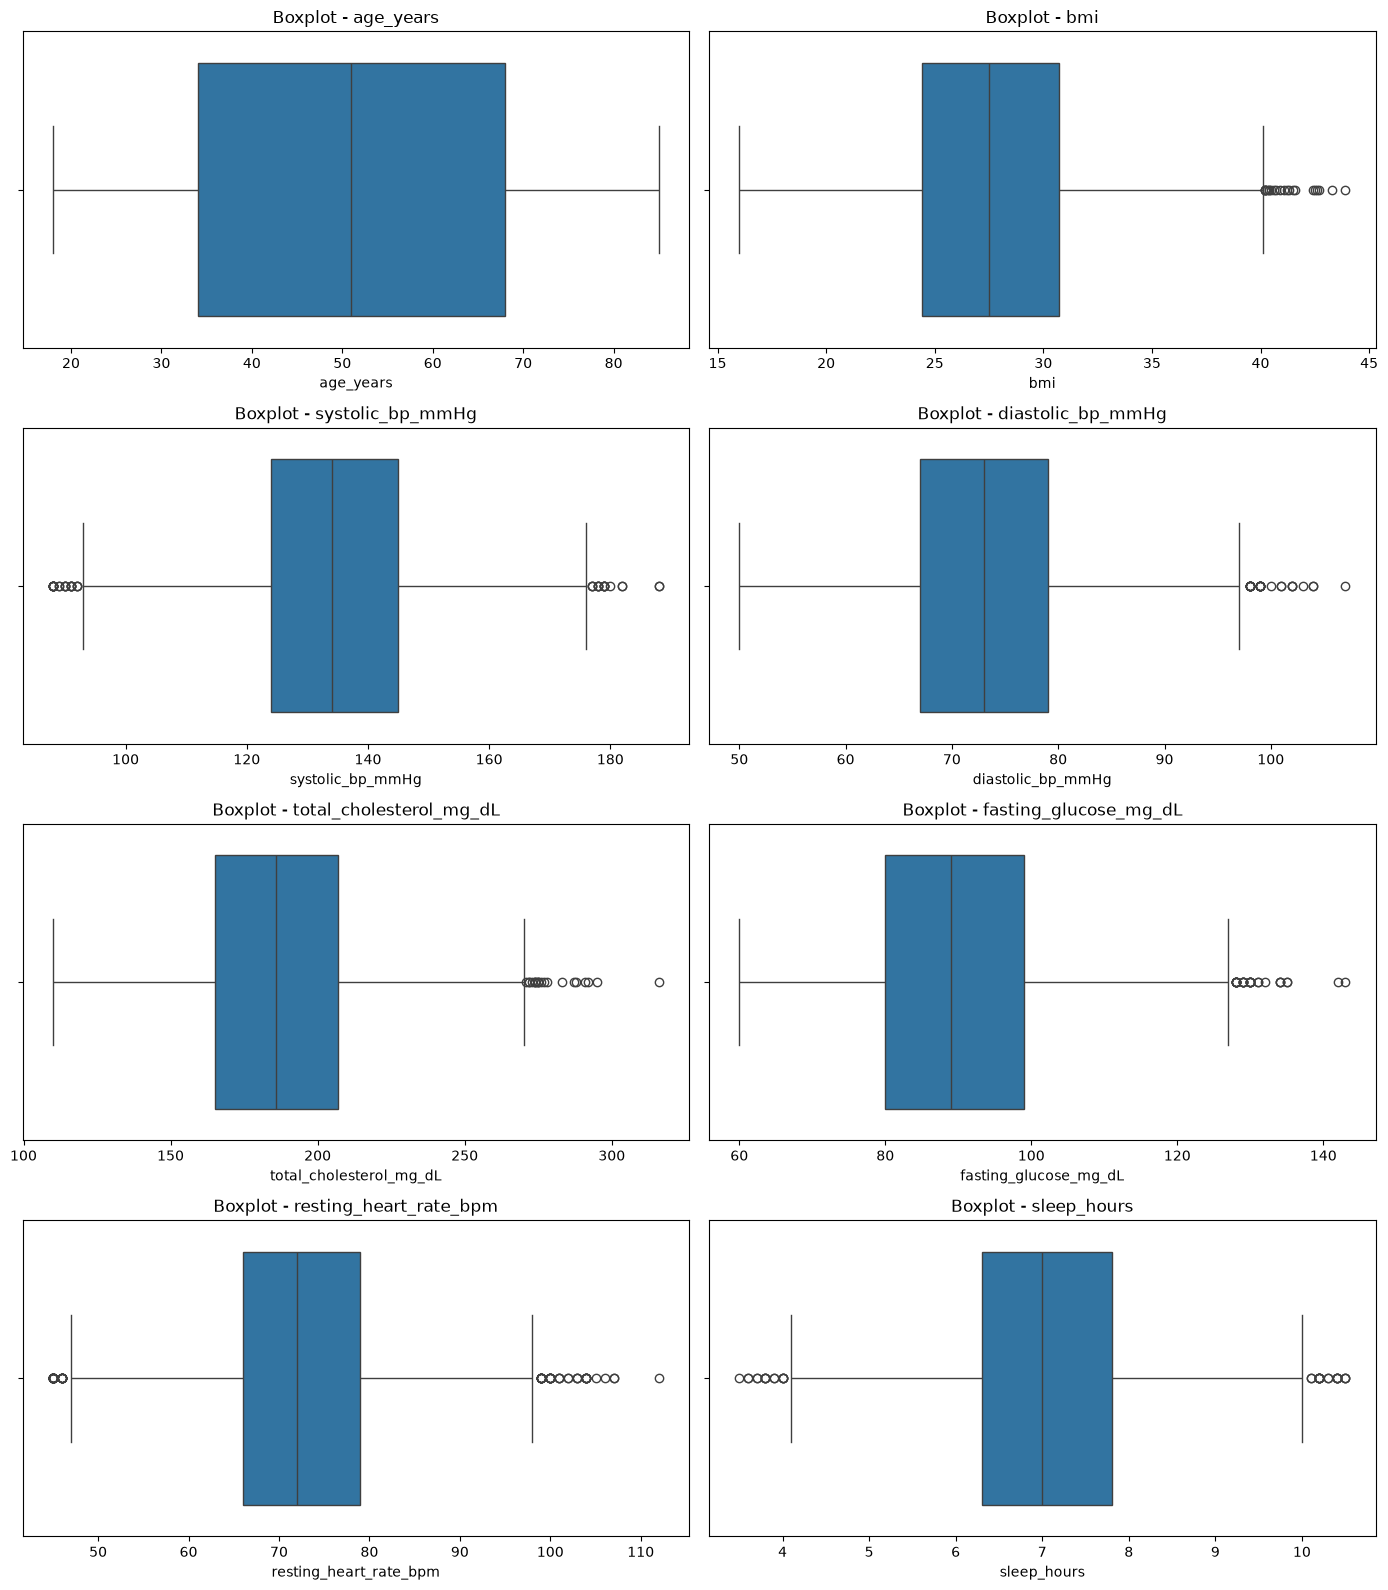

In [92]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.boxplot(
        x=df[col],
        ax=axes[i]
    )
    axes[i].set_title(f"Boxplot - {col}")

plt.tight_layout()
plt.show()

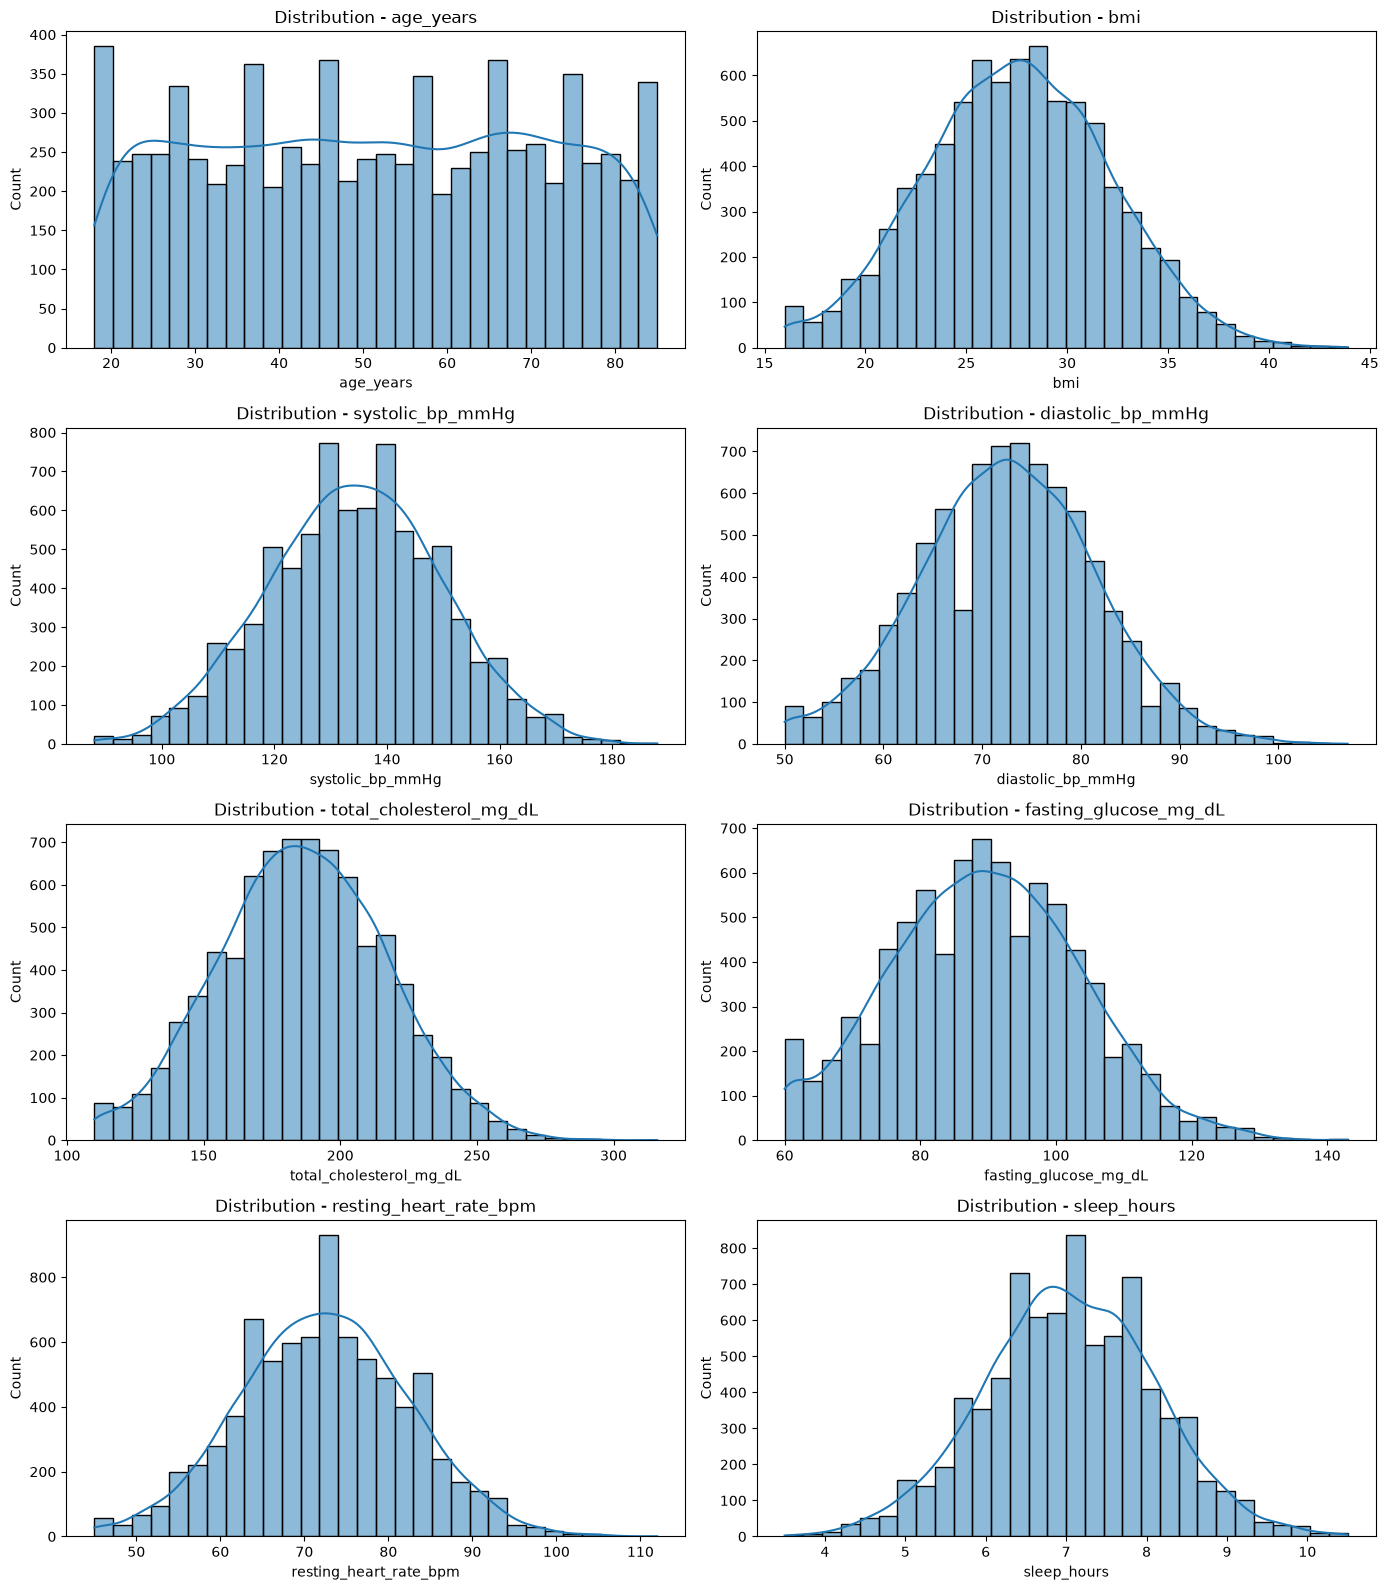

In [93]:
fig, axes = plt.subplots(4, 2, figsize=(14, 16))
axes = axes.flatten()

for i, col in enumerate(numerical_cols):
    sns.histplot(
        df[col],
        kde=True,
        bins=30,
        ax=axes[i]
    )
    axes[i].set_title(f"Distribution - {col}")

plt.tight_layout()
plt.show()

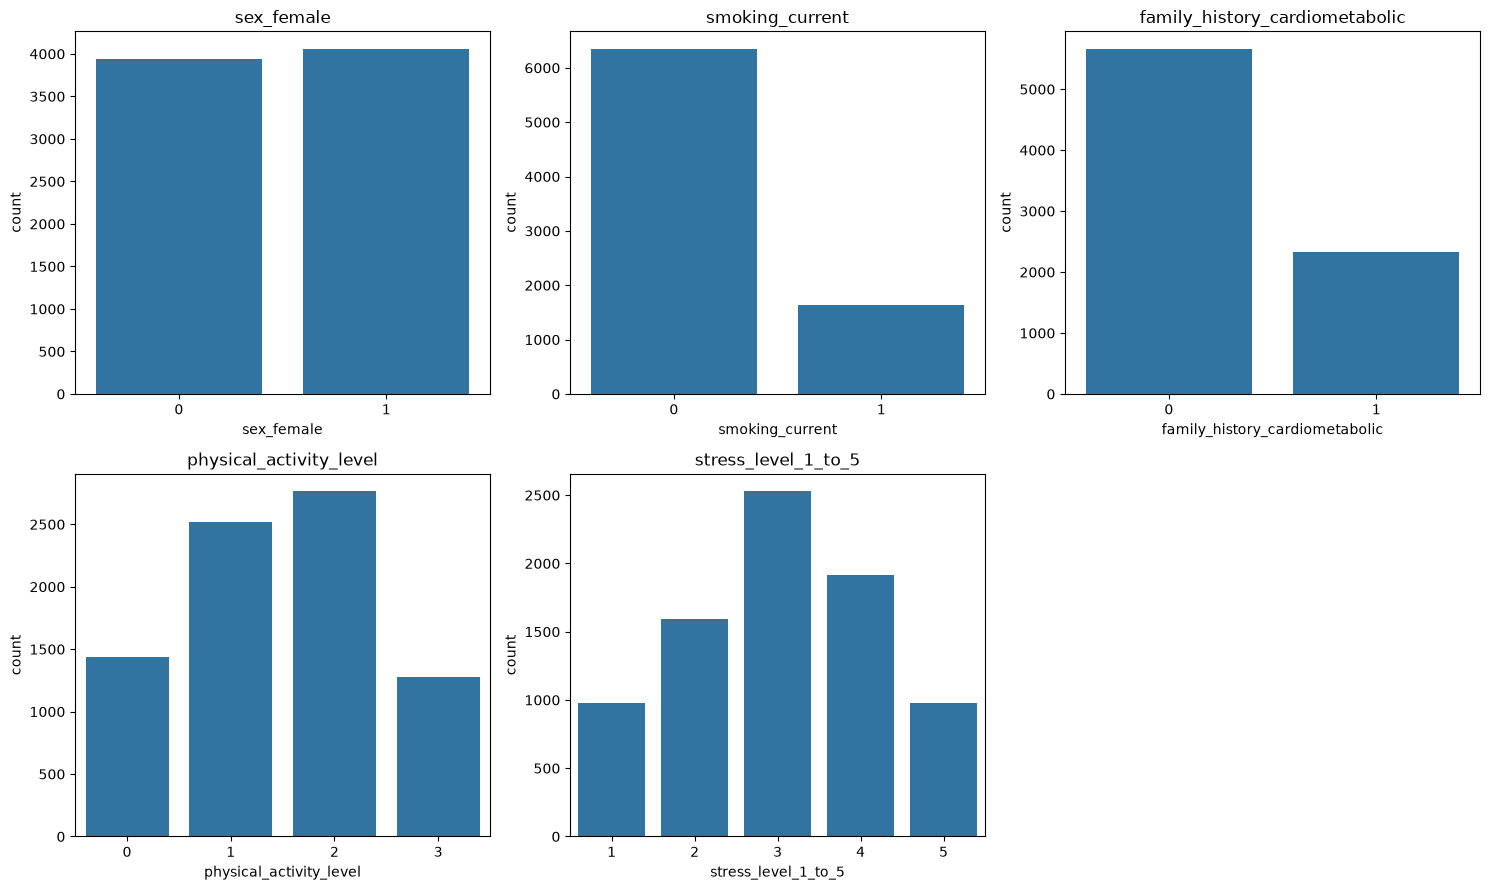

In [94]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
axes = axes.flatten()

for i, col in enumerate(categorical_cols):
    sns.countplot(
        data=df,
        x=col,
        ax=axes[i]
    )
    axes[i].set_title(col)

fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()

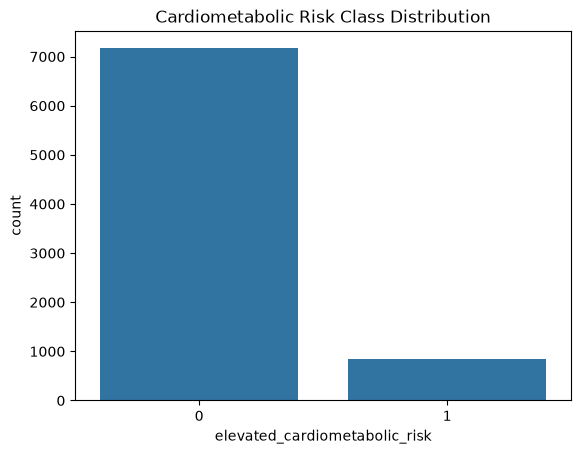

In [95]:
sns.countplot(
    data=df,
    x="elevated_cardiometabolic_risk"
)

plt.title("Cardiometabolic Risk Class Distribution")
plt.show()

In [96]:
feature_cols = df.columns.drop(
    "elevated_cardiometabolic_risk"
)

repeated_features = df[
    df.duplicated(subset=feature_cols, keep=False)
]

print("Rows with identical input features:", len(repeated_features))

display(repeated_features.head(10))

Rows with identical input features: 0


,age_years,sex_female,bmi,systolic_bp_mmHg,diastolic_bp_mmHg,total_cholesterol_mg_dL,fasting_glucose_mg_dL,resting_heart_rate_bpm,smoking_current,family_history_cardiometabolic,physical_activity_level,sleep_hours,stress_level_1_to_5,elevated_cardiometabolic_risk


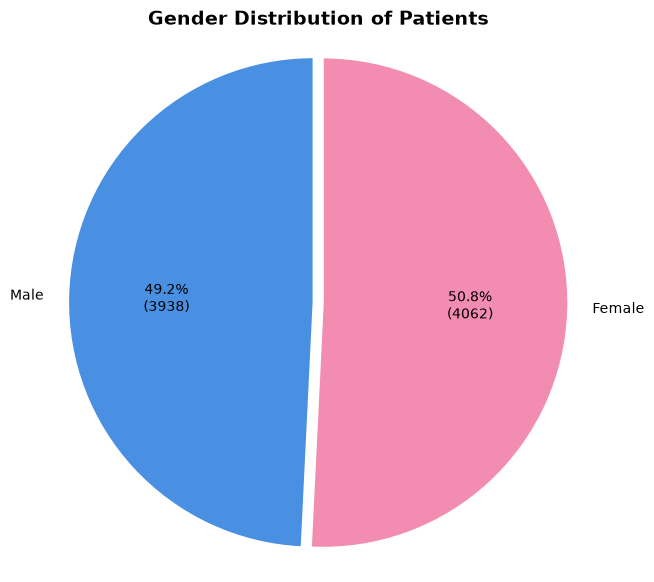

sex_female
Male      3938
Female    4062
Name: count, dtype: int64


In [97]:
import matplotlib.pyplot as plt

# Count male and female records
gender_counts = df["sex_female"].value_counts().reindex([0, 1], fill_value=0)

labels = ["Male", "Female"]
colors = ["#4A90E2", "#F28CB1"]

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=labels,
    colors=colors,
    autopct=lambda pct: f"{pct:.1f}%\n({pct * gender_counts.sum() / 100:.0f})",
    startangle=90,
    explode=(0.02, 0.02),
    wedgeprops={"edgecolor": "white"}
)

plt.title("Gender Distribution of Patients", fontsize=14, fontweight="bold")
plt.axis("equal")
plt.show()

print(gender_counts.rename(index={0: "Male", 1: "Female"}))

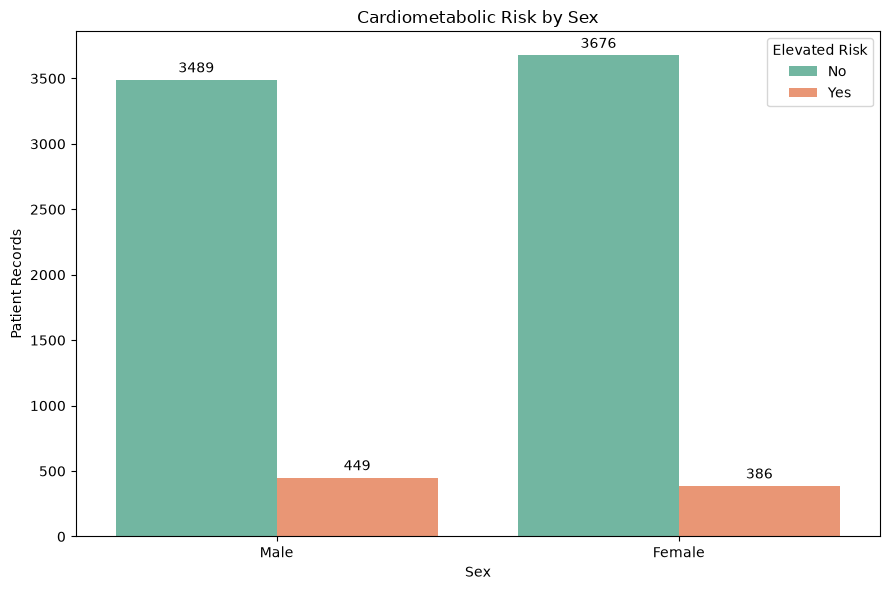

In [98]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

ax = sns.countplot(
    data=df,
    x="sex_female",
    hue="elevated_cardiometabolic_risk",
    palette="Set2"
)

# Display exact counts above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.xticks([0, 1], ["Male", "Female"])
plt.xlabel("Sex")
plt.ylabel("Patient Records")
plt.title("Cardiometabolic Risk by Sex")
plt.legend(title="Elevated Risk", labels=["No", "Yes"])

plt.tight_layout()
plt.show()

In [99]:
pd.crosstab(
    df["sex_female"],
    df["elevated_cardiometabolic_risk"]
).rename(
    index={0: "Male", 1: "Female"},
    columns={0: "No Risk", 1: "Elevated Risk"}
)

elevated_cardiometabolic_risk,No Risk,Elevated Risk
sex_female,,
Male,3489,449
Female,3676,386


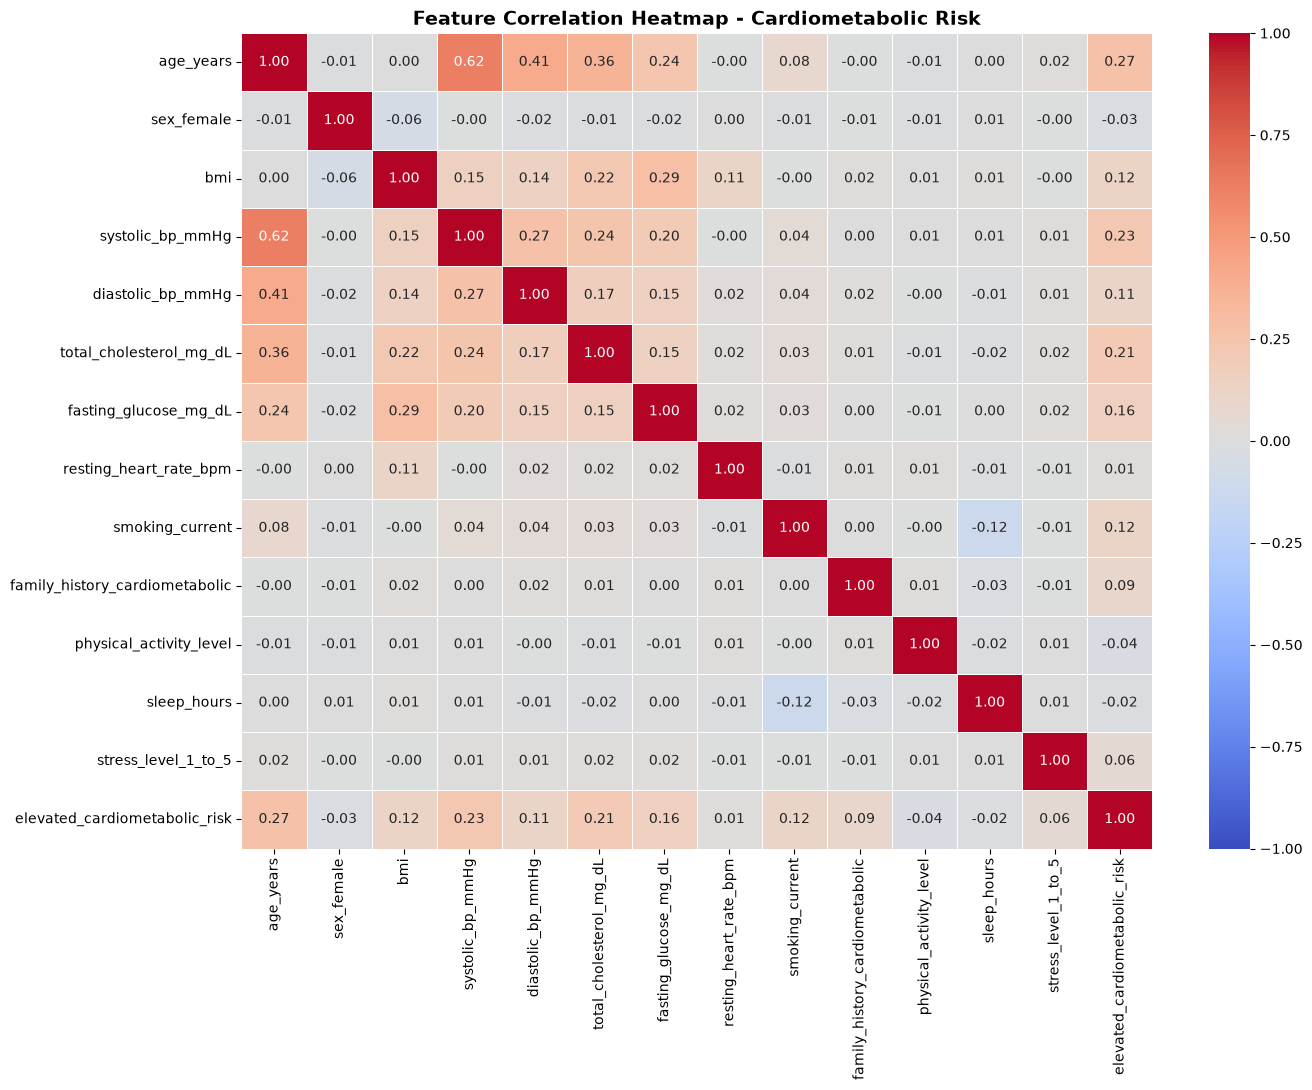

In [100]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation matrix
corr_matrix = df.corr(numeric_only=True)

plt.figure(figsize=(14, 11))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5
)

plt.title(
    "Feature Correlation Heatmap - Cardiometabolic Risk",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [101]:
age_df = df.copy()

age_df["age_group"] = pd.cut(
    age_df["age_years"],
    bins=[0, 30, 40, 50, 60, 70, float("inf")],
    labels=["≤30", "31–40", "41–50", "51–60", "61–70", "70+"],
    include_lowest=True
)

age_risk = (
    age_df.groupby("age_group", observed=False)
    ["elevated_cardiometabolic_risk"]
    .agg(["count", "sum", "mean"])
)

age_risk.columns = [
    "Total_Records",
    "Elevated_Risk_Count",
    "Risk_Rate"
]

age_risk["Risk_Rate"] *= 100

display(age_risk.round(2))

,Total_Records,Elevated_Risk_Count,Risk_Rate
age_group,,,
≤30,1572,25,1.59
31–40,1131,38,3.36
41–50,1204,66,5.48
51–60,1135,108,9.52
61–70,1235,178,14.41
70+,1723,420,24.38


In [102]:

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

# Create age groups
age_df = df.copy()

age_df["age_group"] = pd.cut(
    age_df["age_years"],
    bins=[0, 30, 40, 50, 60, 70, np.inf],
    labels=["≤30", "31–40", "41–50", "51–60", "61–70", "70+"],
    include_lowest=True
)

# Calculate risk percentage per age group
age_risk = (
    age_df.groupby("age_group", observed=False)
    ["elevated_cardiometabolic_risk"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

age_risk["risk_percentage"] = age_risk["mean"] * 100

# Plot setup
fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(age_risk))
values = age_risk["risk_percentage"].to_numpy()

bars = ax.bar(
    x,
    np.zeros(len(values)),
    color="steelblue"
)

ax.set_xticks(x)
ax.set_xticklabels(age_risk["age_group"])
ax.set_ylim(0, max(values.max() * 1.2, 1))
ax.set_xlabel("Age Group")
ax.set_ylabel("Elevated Risk (%)")
ax.set_title("Animated Cardiometabolic Risk by Age Group")

labels = [
    ax.text(i, 0, "", ha="center", va="bottom")
    for i in x
]

# Animation function
def update(frame):
    progress = frame / 50
    heights = values * progress

    for bar, label, height in zip(bars, labels, heights):
        bar.set_height(height)
        label.set_y(height + 0.2)
        label.set_text(f"{height:.1f}%")

    return list(bars) + labels

anim = FuncAnimation(
    fig,
    update,
    frames=51,
    interval=40,
    blit=True,
    repeat=False
)

plt.close(fig)

HTML(anim.to_jshtml())

In [103]:
# All records vs records with at least one IQR outlier

all_records = df.copy()

outlier_records = df.loc[
    outlier_flags.any(axis=1)
].copy()

features = ["age_years", "systolic_bp_mmHg"]

for name, data in [
    ("Entire Dataset", all_records),
    ("Outlier Records", outlier_records)
]:
    print(f"\n{name} - {len(data)} records")

    summary = data.groupby(
        "elevated_cardiometabolic_risk"
    )[features].agg(["count", "mean", "median", "min", "max"])

    display(summary.round(2))


Entire Dataset - 8000 records


age_years                        \
                                  count   mean median min max   
elevated_cardiometabolic_risk                                   
0                                  7165  49.52   49.0  18  85   
1                                   835  66.69   71.0  18  85   

                              systolic_bp_mmHg                          
                                         count    mean median min  max  
elevated_cardiometabolic_risk                                           
0                                         7165  133.02  133.0  88  188  
1                                          835  144.53  145.0  97  188


Outlier Records - 249 records


age_years                        \
                                  count   mean median min max   
elevated_cardiometabolic_risk                                   
0                                   199  51.38   51.0  18  85   
1                                    50  71.56   74.0  48  85   

                              systolic_bp_mmHg                           
                                         count    mean median  min  max  
elevated_cardiometabolic_risk                                            
0                                          199  132.18  135.0   88  188  
1                                           50  153.56  151.5  111  188

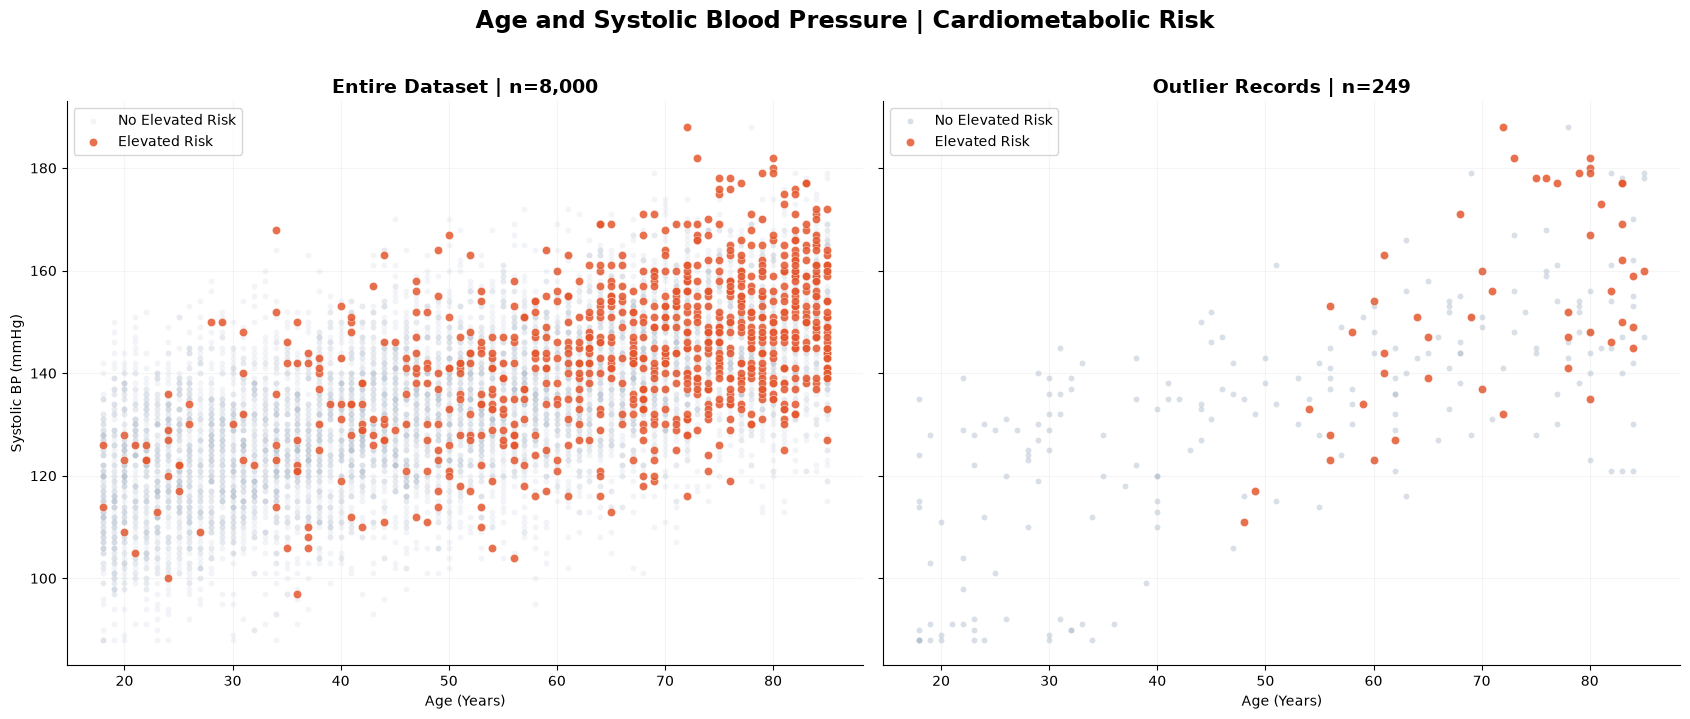

In [104]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 7),
    sharex=True,
    sharey=True
)

datasets = [
    (df, "Entire Dataset | n=8,000"),
    (df.loc[outlier_flags.any(axis=1)], "Outlier Records | n=249")
]

for ax, (data, title) in zip(axes, datasets):

    # Class 0: draw first, as background
    no_risk = data[
        data["elevated_cardiometabolic_risk"] == 0
    ]

    sns.scatterplot(
        data=no_risk,
        x="age_years",
        y="systolic_bp_mmHg",
        color="#A9B8C8",
        alpha=0.14 if len(data) > 1000 else 0.45,
        s=18,
        linewidth=0,
        label="No Elevated Risk",
        ax=ax
    )

    # Class 1: highlight on top
    elevated = data[
        data["elevated_cardiometabolic_risk"] == 1
    ]

    sns.scatterplot(
        data=elevated,
        x="age_years",
        y="systolic_bp_mmHg",
        color="#E4572E",
        alpha=0.85,
        s=35,
        edgecolor="white",
        linewidth=0.3,
        label="Elevated Risk",
        ax=ax
    )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Age (Years)")
    ax.set_ylabel("Systolic BP (mmHg)")
    ax.grid(alpha=0.12)
    ax.legend(loc="upper left")

sns.despine()

fig.suptitle(
    "Age and Systolic Blood Pressure | Cardiometabolic Risk",
    fontsize=17,
    fontweight="bold",
    y=1.02
)

plt.tight_layout()
plt.show()

## Exploratory Data Analysis — Final Findings & Decisions

### 1. Dataset Overview
- Dataset: Synthetic Cardiometabolic Risk Dataset
- Total records: **8,000**
- Input features: **13**
- Target: `elevated_cardiometabolic_risk`
- Problem type: Supervised binary classification.
- Missing values: **0**
- Exact duplicate records: **0**

**Finding:** The dataset is structurally complete, with no missing values or exact duplicate rows.

**Justification:** No missing-value imputation or duplicate removal is required based on these checks. The absence of patient identifiers means repeated visits cannot be independently verified.

### 2. Target Class Distribution

| Class | Records | Percentage |
|---|---:|---:|
| 0 — No elevated risk | 7,165 | 89.56% |
| 1 — Elevated risk | 835 | 10.44% |

**Finding:** The target variable is significantly imbalanced, with approximately 8.6 majority-class records for every minority-class record.

**Decision:** Use stratified data splitting, investigate class weighting during ANN training, and evaluate performance using precision, recall, F1-score, confusion matrix, and PR-AUC rather than accuracy alone.

### 3. Sex Distribution
- Male: **3,938 (49.23%)**
- Female: **4,062 (50.78%)**
- Elevated-risk proportion among males: **11.40%**
- Elevated-risk proportion among females: **9.50%**

**Finding:** Both recorded sex groups have nearly equal representation. Male records show a slightly higher observed elevated-risk proportion.

**Justification:** Balanced representation across sex categories does not eliminate target-class imbalance. The observed group difference does not establish causation.

### 4. Outlier Analysis

Outliers were detected using the 1.5 × IQR method across eight numerical features.

| Feature | Outlier count |
|---|---:|
| Resting heart rate | 80 |
| Systolic blood pressure | 40 |
| Sleep hours | 34 |
| Diastolic blood pressure | 29 |
| Fasting glucose | 29 |
| BMI | 22 |
| Total cholesterol | 20 |
| Age | 0 |

- Records containing at least one outlier: **249 (3.11%)**
- Elevated risk among outlier records: **20.08%**
- Elevated risk among non-outlier records: **10.13%**

**Finding:** Records with statistically extreme measurements exhibit approximately twice the elevated-risk prevalence of non-outlier records.

**Decision:** Retain outliers for initial modeling.

**Justification:** Extreme clinical measurements may represent meaningful physiological conditions rather than data-entry errors. Automatic removal could eliminate useful predictive information. IQR thresholds are statistical and do not independently establish clinical abnormality.

### 5. Correlation Analysis

The strongest observed positive correlations with elevated cardiometabolic risk were:

| Feature | Pearson correlation |
|---|---:|
| Age | +0.27 |
| Systolic BP | +0.23 |
| Total cholesterol | +0.21 |
| Fasting glucose | +0.16 |
| BMI | +0.12 |
| Current smoking | +0.12 |

The strongest notable inter-feature correlation was:

- Age ↔ Systolic BP: **+0.62**

**Finding:** Age, systolic blood pressure, and cholesterol have the highest individual linear associations with the target, although none has a strong correlation.

**Decision:** Retain all 13 predictors for initial modeling.

**Justification:** Correlation alone is insufficient for feature elimination. Neural networks can learn nonlinear relationships and interactions that Pearson correlation may not capture.

### 6. Age-Based Risk Analysis

| Age group | Elevated-risk rate |
|---|---:|
| ≤30 | 1.59% |
| 31–40 | 3.36% |
| 41–50 | 5.48% |
| 51–60 | 9.52% |
| 61–70 | 14.41% |
| 70+ | 24.38% |

**Finding:** Elevated-risk prevalence increases consistently across the observed age groups.

**Justification:** This supports further investigation of age as a potential predictive feature, while not demonstrating causation or independent feature importance.

### 7. Age and Systolic Blood Pressure Analysis

**Entire dataset**

| Metric | Class 0 | Class 1 |
|---|---:|---:|
| Mean age | 49.52 | 66.69 |
| Mean systolic BP | 133.02 | 144.53 |

**Outlier subset**

| Metric | Class 0 | Class 1 |
|---|---:|---:|
| Mean age | 51.38 | 71.56 |
| Mean systolic BP | 132.18 | 153.56 |

**Finding:** Elevated-risk records have higher average age and systolic blood pressure in both populations. The observed differences are larger in the outlier subset.

**Justification:** These patterns support retaining both features and examining their contribution during model evaluation. They do not establish that these are the two most important independent predictors.

### 8. Data Quality and Limitations
- The dataset has no missing values or exact duplicate records.
- No patient identifier or visit timestamp is available.
- The dataset is identified as synthetic.
- The precise methodology used to generate the target labels has not been verified.
- Statistical outliers must not automatically be interpreted as clinical emergencies or incorrect measurements.

**Decision:** Preserve the original observations and avoid modifying target labels based solely on clinical assumptions.

### 9. Final EDA Conclusion

Exploratory analysis identified substantial target-class imbalance, meaningful statistical outliers, and positive associations between elevated cardiometabolic risk and several clinical measurements, particularly age, systolic blood pressure, and cholesterol.

The age-group analysis revealed a consistent increase in elevated-risk prevalence with age. Outlier records also displayed higher elevated-risk prevalence than non-outlier records, supporting the decision to retain statistically extreme but potentially valid measurements.

**The dataset is ready for initial preprocessing and baseline model development**, subject to documenting the unverified target-label methodology.

### 10. Preprocessing Decisions
1. Separate the 13 input features from the target.
2. Perform a stratified training, validation, and test split.
3. Preserve the minority-class distribution across splits.
4. Fit preprocessing transformations using training data only to prevent leakage.
5. Scale continuous numerical features for neural network training.
6. Handle binary and ordinal variables according to their meaning.
7. Retain outliers initially and assess their effects through model evaluation.
8. Consider class weights to address target imbalance.
9. Train a traditional ML baseline before evaluating the ANN.
10. Keep test data untouched until final evaluation.

In [105]:
target = "elevated_cardiometabolic_risk"

X = df.drop(columns=[target])
y = df[target]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts(normalize=True).round(4))

Input shape: (8000, 13)
Target shape: (8000,)

Target distribution:
elevated_cardiometabolic_risk
0    0.8956
1    0.1044
Name: proportion, dtype: float64


In [106]:
from sklearn.model_selection import train_test_split

# First split: 80% train, 20% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Second split: divide temporary data equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Testing:", X_test.shape, y_test.shape)

# Verify class proportions
for name, labels in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(
        f"{name} elevated-risk percentage: "
        f"{labels.mean() * 100:.2f}%"
    )

Training: (6400, 13) (6400,)
Validation: (800, 13) (800,)
Testing: (800, 13) (800,)
Training elevated-risk percentage: 10.44%
Validation elevated-risk percentage: 10.50%
Testing elevated-risk percentage: 10.38%


### Data Splitting — Justification (80:10:10)

**Why Train–Validation–Test instead of Train–Test?**

We selected an **80:10:10 stratified split** to separate model training, hyperparameter tuning, and final evaluation.

1. **Training Set (80% — 6,400 records):** Used to train the ANN by updating weights and biases through backpropagation.

2. **Validation Set (10% — 800 records):** Used to monitor validation loss across epochs, detect overfitting, apply early stopping, and tune hyperparameters such as Dense layers, neurons, learning rate, and batch size.

3. **Test Set (10% — 800 records):** Kept untouched during training and model selection to provide an independent final evaluation of generalization performance.

**Why Stratified Sampling?**

The target is imbalanced, with 89.56% class 0 and 10.44% class 1. Stratification maintains approximately the same class proportions across all three subsets, supporting more representative model evaluation.

**Why Split Before Preprocessing?**

Scaling and encoding transformations that learn parameters from data must be fitted on the training set only. The same fitted transformations are then applied to validation and test sets to prevent data leakage.

**Why This Approach for TensorFlow/Keras?**

Both Sequential and Functional ANN architectures can use identical data partitions, enabling fair comparisons. Validation data supports Keras callbacks such as `EarlyStopping`, while the untouched test set provides the final performance estimate.

**Final Decision:** A dedicated validation set was chosen to support controlled ANN experimentation, reduce overfitting-related model-selection errors, and preserve an independent test set. Cross-validation is also valid, but a fixed validation partition provides a straightforward workflow for this learning project.

In [107]:
continuous_features = [
    "age_years",
    "bmi",
    "systolic_bp_mmHg",
    "diastolic_bp_mmHg",
    "total_cholesterol_mg_dL",
    "fasting_glucose_mg_dL",
    "resting_heart_rate_bpm",
    "sleep_hours"
]

ordinal_features = [
    "physical_activity_level",
    "stress_level_1_to_5"
]

binary_features = [
    "sex_female",
    "smoking_current",
    "family_history_cardiometabolic"
]

print("Continuous:", len(continuous_features))
print("Ordinal:", len(ordinal_features))
print("Binary:", len(binary_features))

print(
    "Total features:",
    len(continuous_features)
    + len(ordinal_features)
    + len(binary_features)
)

Continuous: 8
Ordinal: 2
Binary: 3
Total features: 13


In [108]:
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer

scale_features=continuous_features+ordinal_features

preprocessor=ColumnTransformer(
    transformers=[
        ("scaler", StandardScaler(), scale_features),
        ("binary", "passthrough",binary_features)
    ]
)
X_train_scaled=preprocessor.fit_transform(X_train)
X_val_scaled=preprocessor.transform(X_val)
X_test_scaled=preprocessor.transform(X_test)


print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)



Training: (6400, 13)
Validation: (800, 13)
Testing: (800, 13)


In [109]:
import numpy as np
import tensorflow as tf

# Set seed for reproducibility
tf.keras.utils.set_random_seed(42)

# Training data
X_train_tf = tf.convert_to_tensor(
    X_train_scaled, dtype=tf.float32
)

y_train_tf = tf.convert_to_tensor(
    y_train.to_numpy(), dtype=tf.float32
)

# Validation data
X_val_tf = tf.convert_to_tensor(
    X_val_scaled, dtype=tf.float32
)

y_val_tf = tf.convert_to_tensor(
    y_val.to_numpy(), dtype=tf.float32
)

# Testing data
X_test_tf = tf.convert_to_tensor(
    X_test_scaled, dtype=tf.float32
)

y_test_tf = tf.convert_to_tensor(
    y_test.to_numpy(), dtype=tf.float32
)

print("TensorFlow version:", tf.__version__)
print("Training:", X_train_tf.shape, y_train_tf.shape)
print("Validation:", X_val_tf.shape, y_val_tf.shape)
print("Testing:", X_test_tf.shape, y_test_tf.shape)

TensorFlow version: 2.22.0-rc0
Training: (6400, 13) (6400,)
Validation: (800, 13) (800,)
Testing: (800, 13) (800,)


In [110]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense

# Set seed before model creation
tf.keras.utils.set_random_seed(42)

seq_model = Sequential([
    Input(shape=(13,), name="input_layer"),

    Dense(32, activation="relu", name="hidden_layer_1"),

    Dense(16, activation="relu", name="hidden_layer_2"),

    Dense(1, activation="sigmoid", name="output_layer")
], name="Sequential_ANN")

seq_model.summary()

Model: "Sequential_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ hidden_layer_1 (Dense)          │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_layer_2 (Dense)          │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

In [111]:
from tensorflow.keras import Model
from tensorflow.keras.layers import Input, Dense

# Functional API input
inputs = Input(shape=(13,), name="patient_inputs")

# First hidden layer
x = Dense(32, activation="relu", name="hidden_1")(inputs)

# Second hidden layer
x = Dense(16, activation="relu", name="hidden_2")(x)

# Output layer
outputs = Dense(1, activation="sigmoid", name="risk_output")(x)

# Create model
func_model = Model(
    inputs=inputs,
    outputs=outputs,
    name="Functional_ANN"
)

# Match the Sequential model's initial weights
func_model.set_weights(seq_model.get_weights())

func_model.summary()

Model: "Functional_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ patient_inputs (InputLayer)     │ (None, 13)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_1 (Dense)                │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden_2 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ risk_output (Dense)             │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

In [112]:
import numpy as np

# Check whether both models have identical initial weights
weights_match = all(
    np.array_equal(w1, w2)
    for w1, w2 in zip(
        seq_model.get_weights(),
        func_model.get_weights()
    )
)

# Predict using the same 5 training records
seq_predictions = seq_model(X_train_tf[:5], training=False)
func_predictions = func_model(X_train_tf[:5], training=False)

print("Weights identical:", weights_match)

print(
    "Predictions match:",
    np.allclose(seq_predictions.numpy(),
                func_predictions.numpy(), atol=1e-6)
)

print("\nSequential predictions:")
print(seq_predictions.numpy().flatten())

print("\nFunctional predictions:")
print(func_predictions.numpy().flatten())

Weights identical: True
Predictions match: True

Sequential predictions:
[0.72638327 0.51040274 0.5431978  0.3081421  0.5038442 ]

Functional predictions:
[0.72638327 0.51040274 0.5431978  0.3081421  0.5038442 ]


In [113]:
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.metrics import (
    BinaryAccuracy, Precision, Recall, AUC
)

def compile_ann(model):
    model.compile(
        optimizer=Adam(learning_rate=0.001),

        loss="binary_crossentropy",

        metrics=[
            BinaryAccuracy(name="accuracy"),
            Precision(name="precision"),
            Recall(name="recall"),
            AUC(curve="PR", name="pr_auc")
        ]
    )

compile_ann(seq_model)
compile_ann(func_model)

print("Both ANN models compiled successfully!")

Both ANN models compiled successfully!


In [114]:
from tensorflow.keras.callbacks import EarlyStopping

# Separate callbacks for each model
seq_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

func_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train Sequential ANN
seq_history = seq_model.fit(
    X_train_tf,
    y_train_tf,
    validation_data=(X_val_tf, y_val_tf),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=[seq_early_stopping],
    verbose=1
)

# Train Functional ANN
func_history = func_model.fit(
    X_train_tf,
    y_train_tf,
    validation_data=(X_val_tf, y_val_tf),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=[func_early_stopping],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8820 - loss: 0.3452 - pr_auc: 0.1443 - precision: 0.1009 - recall: 0.0165 - val_accuracy: 0.8950 - val_loss: 0.2945 - val_pr_auc: 0.2629 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8958 - loss: 0.2870 - pr_auc: 0.2860 - precision: 1.0000 - recall: 0.0015 - val_accuracy: 0.8950 - val_loss: 0.2890 - val_pr_auc: 0.2954 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8964 - loss: 0.2797 - pr_auc: 0.3204 - precision: 0.7273 - recall: 0.0120 - val_accuracy: 0.8938 - val_loss: 0.2870 - val_pr_auc: 0.3041 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8966 - loss: 0.2753 - pr_auc: 0.3465 - precision: 0.6364 - recall: 0.0210 - val_accuracy: 0.8950 - val_loss: 0.2854 - val_pr_auc: 0.3167 - val_precision: 0.5000 - val

In [115]:
# Evaluate both models on the same validation data

seq_metrics = seq_model.evaluate(
    X_val_tf,
    y_val_tf,
    return_dict=True,
    verbose=0
)

func_metrics = func_model.evaluate(
    X_val_tf,
    y_val_tf,
    return_dict=True,
    verbose=0
)

import pandas as pd

comparison = pd.DataFrame({
    "Sequential ANN": seq_metrics,
    "Functional ANN": func_metrics
}).T

print(comparison.round(4))

print("\nSequential best val_loss epoch:",
      seq_history.history["val_loss"].index(
          min(seq_history.history["val_loss"])
      ) + 1)

print("Functional best val_loss epoch:",
      func_history.history["val_loss"].index(
          min(func_history.history["val_loss"])
      ) + 1)

                accuracy    loss  pr_auc  precision  recall
Sequential ANN    0.8938  0.2818  0.3396     0.4545  0.0595
Functional ANN    0.8938  0.2818  0.3396     0.4545  0.0595

Sequential best val_loss epoch: 11
Functional best val_loss epoch: 11


In [116]:
import numpy as np
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train.to_numpy()
)

class_weights = {
    int(cls): float(weight)
    for cls, weight in zip(classes, weights)
}

print("Training class counts:")
print(y_train.value_counts().sort_index())

print("\nCalculated class weights:")
print(class_weights)

Training class counts:
elevated_cardiometabolic_risk
0    5732
1     668
Name: count, dtype: int64

Calculated class weights:
{0: 0.5582693649685974, 1: 4.790419161676646}


In [117]:
from tensorflow.keras.models import clone_model

# Create a new ANN with identical architecture
weighted_model = clone_model(seq_model)

# Copy the baseline model's ORIGINAL initial weights
# (We must reconstruct these, not copy its trained weights)
tf.keras.utils.set_random_seed(42)

initial_model = Sequential([
    Input(shape=(13,), name="input_layer"),
    Dense(32, activation="relu", name="hidden_layer_1"),
    Dense(16, activation="relu", name="hidden_layer_2"),
    Dense(1, activation="sigmoid", name="output_layer")
])

weighted_model.set_weights(initial_model.get_weights())

# Same compilation settings as baseline
compile_ann(weighted_model)

print("Weighted ANN parameters:", weighted_model.count_params())
print("Ready for class-weighted training!")

Weighted ANN parameters: 993
Ready for class-weighted training!


In [118]:
from tensorflow.keras.callbacks import EarlyStopping

weighted_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

weighted_history = weighted_model.fit(
    X_train_tf,
    y_train_tf,
    validation_data=(X_val_tf, y_val_tf),
    epochs=50,
    batch_size=32,
    shuffle=False,
    class_weight=class_weights,
    callbacks=[weighted_early_stopping],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.6550 - loss: 0.6098 - pr_auc: 0.2369 - precision: 0.1810 - recall: 0.6542 - val_accuracy: 0.6538 - val_loss: 0.5704 - val_pr_auc: 0.2924 - val_precision: 0.2049 - val_recall: 0.7976
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6812 - loss: 0.5454 - pr_auc: 0.3309 - precision: 0.2182 - recall: 0.7949 - val_accuracy: 0.6975 - val_loss: 0.5573 - val_pr_auc: 0.3258 - val_precision: 0.2295 - val_recall: 0.7976
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6975 - loss: 0.5328 - pr_auc: 0.3575 - precision: 0.2263 - recall: 0.7844 - val_accuracy: 0.7100 - val_loss: 0.5515 - val_pr_auc: 0.3416 - val_precision: 0.2338 - val_recall: 0.7738
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7077 - loss: 0.5261 - pr_auc: 0.3699 - precision: 0.2321 - recall: 0.7799 - val_accuracy: 0.7225 - val_loss: 0.5509 - val_pr_auc: 0.3391 - val_precision: 0.2425 - val_recall: 0.7738
Epoch 5/

In [119]:
# Evaluate weighted model
weighted_metrics = weighted_model.evaluate(
    X_val_tf,
    y_val_tf,
    return_dict=True,
    verbose=0
)

# Compare both models
comparison = pd.DataFrame({
    "Baseline ANN": seq_metrics,
    "Weighted ANN": weighted_metrics
}).T

print(comparison.round(4))

# Best validation-loss epoch
best_epoch = np.argmin(
    weighted_history.history["val_loss"]
) + 1

print("\nWeighted ANN best epoch:", best_epoch)

              accuracy    loss  pr_auc  precision  recall
Baseline ANN    0.8938  0.2818  0.3396     0.4545  0.0595
Weighted ANN    0.7475  0.5081  0.3235     0.2457  0.6786

Weighted ANN best epoch: 48


In [120]:
from sklearn.metrics import confusion_matrix, classification_report

y_true = y_val.to_numpy()

for name, model in [
    ("Baseline ANN", seq_model),
    ("Weighted ANN", weighted_model)
]:
    probabilities = model.predict(X_val_tf, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    print(f"\n{name}")
    print("Confusion Matrix:")
    print(confusion_matrix(y_true, predictions))

    print("\nClassification Report:")
    print(classification_report(
        y_true, predictions,
        digits=4,
        zero_division=0
    ))


Baseline ANN
Confusion Matrix:
[[710   6]
 [ 79   5]]

Classification Report:
              precision    recall  f1-score   support

           0     0.8999    0.9916    0.9435       716
           1     0.4545    0.0595    0.1053        84

    accuracy                         0.8938       800
   macro avg     0.6772    0.5256    0.5244       800
weighted avg     0.8531    0.8938    0.8555       800


Weighted ANN
Confusion Matrix:
[[541 175]
 [ 27  57]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9525    0.7556    0.8427       716
           1     0.2457    0.6786    0.3608        84

    accuracy                         0.7475       800
   macro avg     0.5991    0.7171    0.6017       800
weighted avg     0.8783    0.7475    0.7921       800



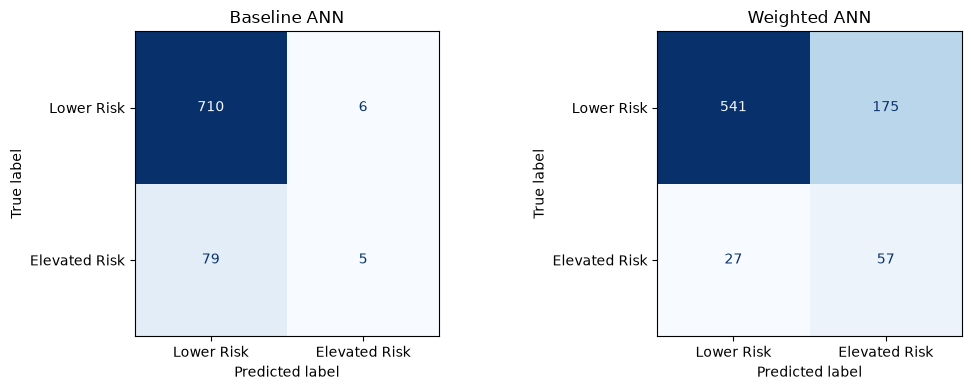

In [121]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(
    axes,
    [
        ("Baseline ANN", seq_model),
        ("Weighted ANN", weighted_model)
    ]
):
    probabilities = model.predict(X_val_tf, verbose=0).ravel()
    predictions = (probabilities >= 0.5).astype(int)

    ConfusionMatrixDisplay.from_predictions(
        y_val.to_numpy(),
        predictions,
        display_labels=["Lower Risk", "Elevated Risk"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )

    ax.set_title(name)

plt.tight_layout()
plt.show()

In [122]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout
from tensorflow.keras.regularizers import l2

tf.keras.utils.set_random_seed(42)

regularized_model = Sequential([
    Input(shape=(13,)),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),
    Dropout(0.2),

    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dense(1, activation="sigmoid")
], name="Regularized_ANN")

regularized_model.summary()

Model: "Regularized_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_10 (Dense)                │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

In [123]:
#  using the same settings as our baseline
compile_ann(regularized_model)

# Early stopping
regularized_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

# Train the regularized ANN
regularized_history = regularized_model.fit(
    X_train_tf,
    y_train_tf,
    validation_data=(X_val_tf, y_val_tf),
    epochs=50,
    batch_size=32,
    shuffle=False,
    callbacks=[regularized_early_stopping],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.8653 - loss: 0.4231 - pr_auc: 0.1277 - precision: 0.1151 - recall: 0.0434 - val_accuracy: 0.8950 - val_loss: 0.3339 - val_pr_auc: 0.2712 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - accuracy: 0.8958 - loss: 0.3301 - pr_auc: 0.2524 - precision: 1.0000 - recall: 0.0015 - val_accuracy: 0.8950 - val_loss: 0.3202 - val_pr_auc: 0.3073 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8958 - loss: 0.3184 - pr_auc: 0.2797 - precision: 1.0000 - recall: 0.0015 - val_accuracy: 0.8950 - val_loss: 0.3137 - val_pr_auc: 0.3163 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8966 - loss: 0.3088 - pr_auc: 0.3068 - precision: 0.8750 - recall: 0.0105 - val_accuracy: 0.8950 - val_loss: 0.3081 - val_pr_auc: 0.3319 - val_precision: 0.0000e+00 -

In [124]:
# Evaluate Regularized ANN
regularized_metrics = regularized_model.evaluate(
    X_val_tf,
    y_val_tf,
    return_dict=True,
    verbose=0
)

# Compare all three models
comparison = pd.DataFrame({
    "Baseline ANN": seq_metrics,
    "Weighted ANN": weighted_metrics,
    "Regularized ANN": regularized_metrics
}).T

# Display key evaluation metrics
print(
    comparison[
        ["accuracy", "precision", "recall", "pr_auc", "loss"]
    ].round(4)
)

# Identify best epoch for Regularized ANN
best_epoch = np.argmin(
    regularized_history.history["val_loss"]
) + 1

print("\nRegularized ANN best epoch:", best_epoch)

                 accuracy  precision  recall  pr_auc    loss
Baseline ANN       0.8938     0.4545  0.0595  0.3396  0.2818
Weighted ANN       0.7475     0.2457  0.6786  0.3235  0.5081
Regularized ANN    0.9000     0.6111  0.1310  0.3587  0.2857

Regularized ANN best epoch: 50


In [125]:
from sklearn.metrics import (
    precision_score,
    recall_score,
    fbeta_score
)
import pandas as pd
import numpy as np

models = {
    "Baseline": seq_model,
    "Weighted": weighted_model,
    "Regularized": regularized_model
}

thresholds = np.arange(0.10, 0.51, 0.05)
results = []

for name, model in models.items():
    probabilities = model.predict(
        X_val_tf, verbose=0
    ).ravel()

    for threshold in thresholds:
        predictions = (
            probabilities >= threshold
        ).astype(int)

        results.append({
            "Model": name,
            "Threshold": round(float(threshold), 2),
            "Precision": precision_score(
                y_val, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_val, predictions, zero_division=0
            ),
            "F2": fbeta_score(
                y_val, predictions,
                beta=2, zero_division=0
            ),
            "False Positives": int(
                ((y_val.to_numpy() == 0) &
                 (predictions == 1)).sum()
            ),
            "False Negatives": int(
                ((y_val.to_numpy() == 1) &
                 (predictions == 0)).sum()
            )
        })

threshold_results = pd.DataFrame(results)

print(threshold_results.round(3).to_string(index=False))

      Model  Threshold  Precision  Recall    F2  False Positives  False Negatives
   Baseline       0.10      0.243   0.798 0.547              209               17
   Baseline       0.15      0.258   0.607 0.478              147               33
   Baseline       0.20      0.324   0.571 0.496              100               36
   Baseline       0.25      0.336   0.452 0.423               75               46
   Baseline       0.30      0.412   0.333 0.347               40               56
   Baseline       0.35      0.400   0.262 0.281               33               62
   Baseline       0.40      0.415   0.202 0.225               24               67
   Baseline       0.45      0.458   0.131 0.153               13               73
   Baseline       0.50      0.455   0.060 0.072                6               79
   Weighted       0.10      0.145   0.905 0.442              447                8
   Weighted       0.15      0.163   0.881 0.468              381               10
   Weighted     

In [126]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

best_results = []

for name, model in models.items():
    probabilities = model.predict(X_val_tf, verbose=0).ravel()

    precision, recall, thresholds = precision_recall_curve(
        y_val.to_numpy(), probabilities
    )

    # The final precision/recall point has no corresponding threshold
    p = precision[:-1]
    r = recall[:-1]

    f2 = (5 * p * r) / (4 * p + r + 1e-12)

    best_idx = np.argmax(f2)

    best_results.append({
        "Model": name,
        "Best Threshold": thresholds[best_idx],
        "Precision": p[best_idx],
        "Recall": r[best_idx],
        "F2": f2[best_idx]
    })

best_thresholds = pd.DataFrame(best_results)

print(best_thresholds.round(4).to_string(index=False))

      Model  Best Threshold  Precision  Recall     F2
   Baseline          0.1060     0.2491  0.7976 0.5537
   Weighted          0.3743     0.2265  0.7738 0.5217
Regularized          0.0870     0.2419  0.7976 0.5465


In [127]:
from sklearn.metrics import confusion_matrix

for _, row in best_thresholds.iterrows():
    name = row["Model"]
    threshold = row["Best Threshold"]

    model = models[name]

    probabilities = model.predict(
        X_val_tf, verbose=0
    ).ravel()

    predictions = (probabilities >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val.to_numpy(),
        predictions,
        labels=[0, 1]
    ).ravel()

    print(f"\n{name} ANN — Threshold: {threshold:.4f}")
    print(f"True Positives:  {tp}")
    print(f"False Negatives: {fn}")
    print(f"False Positives: {fp}")
    print(f"True Negatives:  {tn}")


Baseline ANN — Threshold: 0.1060
True Positives:  67
False Negatives: 17
False Positives: 202
True Negatives:  514

Weighted ANN — Threshold: 0.3743
True Positives:  65
False Negatives: 19
False Positives: 222
True Negatives:  494

Regularized ANN — Threshold: 0.0870
True Positives:  67
False Negatives: 17
False Positives: 210
True Negatives:  506


In [128]:
tf.keras.utils.set_random_seed(42)

combined_model = Sequential([
    Input(shape=(13,)),

    Dense(
        32,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dropout(0.2),

    Dense(
        16,
        activation="relu",
        kernel_regularizer=l2(0.001)
    ),

    Dense(1, activation="sigmoid")
], name="Weighted_Regularized_ANN")

compile_ann(combined_model)

combined_model.summary()

Model: "Weighted_Regularized_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_13 (Dense)                │ (None, 32)             │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 993 (3.88 KB)

 Trainable params: 993 (3.88 KB)

 Non-trainable params: 0 (0.00 B)

In [129]:
combined_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

combined_history = combined_model.fit(
    X_train_tf,
    y_train_tf,
    validation_data=(X_val_tf, y_val_tf),
    epochs=50,
    batch_size=32,
    shuffle=False,
    class_weight=class_weights,
    callbacks=[combined_early_stopping],
    verbose=1
)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.6328 - loss: 0.6477 - pr_auc: 0.2377 - precision: 0.1797 - recall: 0.7066 - val_accuracy: 0.6725 - val_loss: 0.6115 - val_pr_auc: 0.2868 - val_precision: 0.2053 - val_recall: 0.7381
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6837 - loss: 0.5918 - pr_auc: 0.3027 - precision: 0.2144 - recall: 0.7620 - val_accuracy: 0.6963 - val_loss: 0.5876 - val_pr_auc: 0.3010 - val_precision: 0.2230 - val_recall: 0.7619
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.6902 - loss: 0.5810 - pr_auc: 0.3223 - precision: 0.2191 - recall: 0.7680 - val_accuracy: 0.7025 - val_loss: 0.5827 - val_pr_auc: 0.3067 - val_precision: 0.2270 - val_recall: 0.7619
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7025 - loss: 0.5660 - pr_auc: 0.3305 - precision: 0.2311 - recall: 0.7949 - val_accuracy: 0.7150 - val_loss: 0.5717 - val_pr_auc: 0.3234 - val_precision: 0.2372 - val_recall: 0.7738
Epoch 5/

In [130]:
# Evaluate Combined ANN
combined_metrics = combined_model.evaluate(
    X_val_tf,
    y_val_tf,
    return_dict=True,
    verbose=0
)

# Compare all four models
comparison = pd.DataFrame({
    "Baseline ANN": seq_metrics,
    "Functional ANN": func_metrics,
    "Weighted ANN": weighted_metrics,
    "Regularized ANN": regularized_metrics,
    "Combined ANN": combined_metrics
}).T

print(
    comparison[
        ["accuracy", "precision", "recall", "pr_auc", "loss"]
    ].round(4)
)

# Identify Combined ANN's best epoch
best_epoch = np.argmin(
    combined_history.history["val_loss"]
) + 1

print("\nCombined ANN best epoch:", best_epoch)

                 accuracy  precision  recall  pr_auc    loss
Baseline ANN       0.8938     0.4545  0.0595  0.3396  0.2818
Functional ANN     0.8938     0.4545  0.0595  0.3396  0.2818
Weighted ANN       0.7475     0.2457  0.6786  0.3235  0.5081
Regularized ANN    0.9000     0.6111  0.1310  0.3587  0.2857
Combined ANN       0.7387     0.2407  0.6905  0.3651  0.5375

Combined ANN best epoch: 31


In [131]:
from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix
)
import numpy as np

# Get validation probabilities
combined_probs = combined_model.predict(
    X_val_tf, verbose=0
).ravel()

# Calculate precision-recall curve
precision, recall, thresholds = precision_recall_curve(
    y_val.to_numpy(),
    combined_probs
)

# Calculate F2-score for each threshold
p = precision[:-1]
r = recall[:-1]

f2 = (5 * p * r) / (4 * p + r + 1e-12)

# Select threshold with highest F2-score
best_idx = np.argmax(f2)
best_threshold = thresholds[best_idx]

# Predict using selected threshold
predictions = (combined_probs >= best_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_val.to_numpy(),
    predictions,
    labels=[0, 1]
).ravel()

print("Combined ANN — Optimized Threshold")
print(f"Threshold: {best_threshold:.4f}")
print(f"Precision: {p[best_idx]:.4f}")
print(f"Recall:    {r[best_idx]:.4f}")
print(f"F2-score:  {f2[best_idx]:.4f}")
print(f"TP: {tp}, FP: {fp}, FN: {fn}, TN: {tn}")

Combined ANN — Optimized Threshold
Threshold: 0.4550
Precision: 0.2435
Recall:    0.7857
F2-score:  0.5437
TP: 66, FP: 205, FN: 18, TN: 511


In [132]:
from sklearn.metrics import precision_recall_curve
import numpy as np
import pandas as pd

models = {
    "Baseline": seq_model,
    "Weighted": weighted_model,
    "Regularized": regularized_model,
    "Combined": combined_model
}

results = []

for name, model in models.items():

    probs = model.predict(X_val_tf, verbose=0).ravel()

    precision, recall, thresholds = precision_recall_curve(
        y_val.to_numpy(), probs
    )

    p = precision[:-1]
    r = recall[:-1]

    f1 = 2 * p * r / (p + r + 1e-12)

    # Require at least 50% recall
    valid = np.where(r >= 0.50)[0]

    if len(valid) == 0:
        continue

    best_idx = valid[np.argmax(f1[valid])]

    results.append({
        "Model": name,
        "Threshold": thresholds[best_idx],
        "Precision": p[best_idx],
        "Recall": r[best_idx],
        "F1": f1[best_idx]
    })

balanced_results = pd.DataFrame(results)

print(
    balanced_results
    .sort_values("F1", ascending=False)
    .round(4)
    .to_string(index=False)
)

      Model  Threshold  Precision  Recall     F1
   Baseline     0.2090     0.3429  0.5714 0.4286
   Combined     0.6733     0.3154  0.5595 0.4034
   Weighted     0.6474     0.3133  0.5595 0.4017
Regularized     0.1598     0.2941  0.5952 0.3937


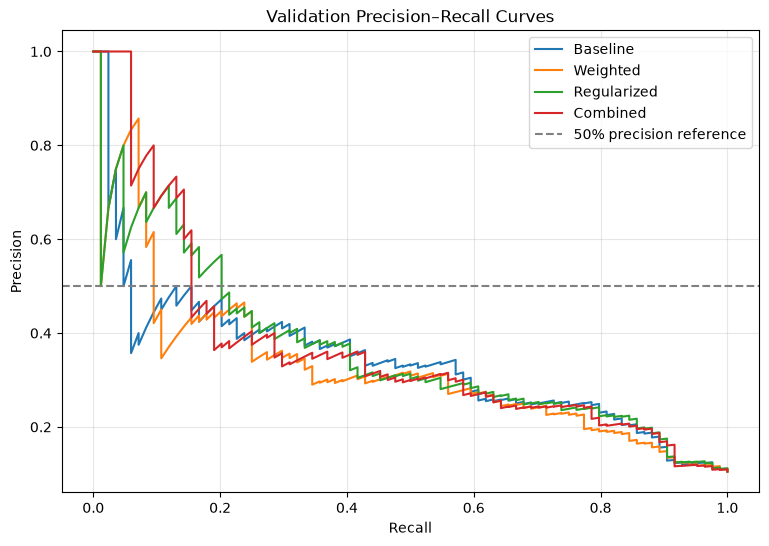

In [133]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 6))

for name, model in models.items():
    probabilities = model.predict(
        X_val_tf, verbose=0
    ).ravel()

    precision, recall, _ = precision_recall_curve(
        y_val.to_numpy(), probabilities
    )

    plt.plot(recall, precision, label=name)

plt.axhline(0.50, linestyle="--", color="gray",
            label="50% precision reference")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision–Recall Curves")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [134]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

lr_model.fit(X_train_scaled, y_train)

lr_probs = lr_model.predict_proba(X_val_scaled)[:, 1]

print(
    "Logistic Regression PR-AUC:",
    round(average_precision_score(y_val, lr_probs), 4)
)

Logistic Regression PR-AUC: 0.3679


In [135]:
from sklearn.metrics import average_precision_score
import pandas as pd

all_models = {
    "Baseline ANN": seq_model,
    "Functional ANN": func_model,
    "Weighted ANN": weighted_model,
    "Regularized ANN": regularized_model,
    "Combined ANN": combined_model
}

ap_results = []

for name, model in all_models.items():
    probs = model.predict(X_val_tf, verbose=0).ravel()

    ap_results.append({
        "Model": name,
        "Average Precision": average_precision_score(
            y_val, probs
        )
    })

ap_results.append({
    "Model": "Logistic Regression",
    "Average Precision": average_precision_score(
        y_val, lr_probs
    )
})

ap_comparison = pd.DataFrame(ap_results)

print(
    ap_comparison
    .sort_values("Average Precision", ascending=False)
    .round(4)
    .to_string(index=False)
)

              Model  Average Precision
Logistic Regression             0.3679
       Combined ANN             0.3664
    Regularized ANN             0.3633
       Baseline ANN             0.3432
     Functional ANN             0.3432
       Weighted ANN             0.3296


In [136]:
from sklearn.metrics import precision_recall_curve
import numpy as np

precision, recall, thresholds = precision_recall_curve(
    y_val.to_numpy(),
    lr_probs
)

p = precision[:-1]
r = recall[:-1]

f1 = 2 * p * r / (p + r + 1e-12)

valid = np.where(r >= 0.50)[0]

if len(valid) > 0:
    best_idx = valid[np.argmax(f1[valid])]

    lr_best_threshold = thresholds[best_idx]

    print("Logistic Regression")
    print(f"Best Threshold: {lr_best_threshold:.4f}")
    print(f"Precision: {p[best_idx]:.4f}")
    print(f"Recall: {r[best_idx]:.4f}")
    print(f"F1-score: {f1[best_idx]:.4f}")
else:
    print("No threshold satisfies the recall requirement.")

Logistic Regression
Best Threshold: 0.2054
Precision: 0.3050
Recall: 0.5119
F1-score: 0.3822


In [137]:
# Freeze our selected ANN configuration
final_model = seq_model

final_threshold = float(
    balanced_results.loc[
        balanced_results["Model"] == "Baseline",
        "Threshold"
    ].iloc[0]
)

print("Selected model:", final_model.name)
print(f"Selected threshold: {final_threshold:.6f}")
print("Selection metric: Validation F1 with recall >= 0.50")

Selected model: Sequential_ANN
Selected threshold: 0.209026
Selection metric: Validation F1 with recall >= 0.50


In [138]:
import os
import joblib
import json

# Create directory
os.makedirs("saved_models", exist_ok=True)

# 1. Save trained ANN
final_model.save("saved_models/cardiometabolic_ann.keras")

# 2. Save fitted preprocessing pipeline
joblib.dump(
    preprocessor,
    "saved_models/preprocessor.joblib"
)

# 3. Save selected classification threshold
with open("saved_models/threshold.json", "w") as f:
    json.dump({
        "threshold": float(final_threshold),
        "model": "Baseline Sequential ANN",
        "selection_metric": "Validation F1 with recall >= 0.50"
    }, f, indent=4)

print("Model, preprocessor and threshold saved successfully!")

Model, preprocessor and threshold saved successfully!


In [139]:
import tensorflow as tf
import joblib
import json
import numpy as np

# 1. Reload trained ANN
loaded_model = tf.keras.models.load_model(
    "saved_models/cardiometabolic_ann.keras"
)

# 2. Reload fitted preprocessor
loaded_preprocessor = joblib.load(
    "saved_models/preprocessor.joblib"
)

# 3. Reload selected threshold
with open("saved_models/threshold.json", "r") as f:
    metadata = json.load(f)

loaded_threshold = float(metadata["threshold"])

# 4. Verify preprocessing on validation data
loaded_X_val = loaded_preprocessor.transform(X_val)

print(
    "Preprocessing matches:",
    np.allclose(loaded_X_val, X_val_scaled)
)

# 5. Verify predictions on validation data
original_probs = final_model.predict(
    X_val_tf, verbose=0
)

loaded_probs = loaded_model.predict(
    loaded_X_val, verbose=0
)

print(
    "Predictions match:",
    np.allclose(original_probs, loaded_probs, atol=1e-6)
)

print("Loaded threshold:", loaded_threshold)
print("Loaded model parameters:", loaded_model.count_params())

Preprocessing matches: True
Predictions match: True
Loaded threshold: 0.20902620255947113
Loaded model parameters: 993


In [140]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Apply saved preprocessing to test data
X_test_processed = loaded_preprocessor.transform(X_test)

# Predict probabilities using saved ANN
test_probs = loaded_model.predict(
    X_test_processed,
    verbose=0
).ravel()

# Apply our previously selected threshold
test_preds = (test_probs >= loaded_threshold).astype(int)

# Actual test labels
y_true = y_test.to_numpy()

# Calculate test metrics
print("FINAL TEST RESULTS")
print("----------------------------")

print("Accuracy:", round(accuracy_score(y_true, test_preds), 4))
print("Precision:", round(precision_score(y_true, test_preds, zero_division=0), 4))
print("Recall:", round(recall_score(y_true, test_preds, zero_division=0), 4))
print("F1-score:", round(f1_score(y_true, test_preds, zero_division=0), 4))
print("Average Precision:", round(average_precision_score(y_true, test_probs), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_true, test_preds, labels=[0, 1]))

print("\nClassification Report:")
print(classification_report(y_true, test_preds, digits=4, zero_division=0))

FINAL TEST RESULTS
----------------------------
Accuracy: 0.8413
Precision: 0.3197
Recall: 0.4699
F1-score: 0.3805
Average Precision: 0.3187

Confusion Matrix:
[[634  83]
 [ 44  39]]

Classification Report:
              precision    recall  f1-score   support

           0     0.9351    0.8842    0.9090       717
           1     0.3197    0.4699    0.3805        83

    accuracy                         0.8413       800
   macro avg     0.6274    0.6771    0.6447       800
weighted avg     0.8713    0.8413    0.8541       800



## Final Model Evaluation and Findings

**Selected model:** Baseline Sequential ANN (13 → 32 → 16 → 1), trained with Adam and binary cross-entropy.

**Selection strategy:** Validation F1-score maximization with a minimum recall requirement of 50%.

**Final classification threshold:** Approximately 0.2090, selected using validation data.

### Final Test Results

| Metric | Value |
|---|---:|
| Accuracy | 84.13% |
| Precision | 31.97% |
| Recall | 46.99% |
| F1-score | 0.3805 |
| Average Precision | 0.3187 |
| True Positives | 39 |
| False Positives | 83 |
| True Negatives | 634 |
| False Negatives | 44 |

### Key Findings

- Sequential and Functional APIs produced identical results with equivalent architectures and controlled initial weights.
- Class weighting improved recall at the default threshold of 0.5 but reduced precision.
- L2 regularization and Dropout were evaluated as generalization techniques.
- Classification threshold selection significantly affected precision and recall.
- The baseline ANN achieved the best validation F1-score under the selected recall constraint.
- Final test results were weaker than validation results, indicating limited generalization at the chosen threshold.
- The model missed 44 of 83 elevated-risk test records and is not suitable for clinical deployment.

**Conclusion:** The project demonstrates an end-to-end TensorFlow/Keras ANN classification workflow. Further work should focus on stronger predictive features, data quality, improved validation procedures, calibration, and independent evaluation before considering real-world use.